# Homework 6 - Banking77 data & model testing

In [1]:
import os

os.environ["TOKENIZERS_PARALLELISM"] = "false"

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

pd.set_option("display.max_colwidth", None)

if torch.cuda.is_available():
    device = "cuda"
elif torch.backends.mps.is_available():
    device = "mps"
else:
    device = "cpu"

NUM_CORES = joblib.cpu_count(only_physical_cores=True)

## 1. Data loading, exploration and cleaning

In [2]:
from datasets import load_dataset

banking77 = load_dataset("PolyAI/banking77")
label_names = banking77["train"].features["label"].names
NUM_LABELS = len(label_names)

df_train_raw = banking77["train"].to_pandas()
df_test_raw = banking77["test"].to_pandas()

print("Train texts:", len(df_train_raw))
print("Test texts:", len(df_test_raw))
print("Number of labels:", NUM_LABELS, f"(min {df_train_raw['label'].min()}, max {df_train_raw['label'].max()})")
display(df_train_raw.dtypes)
display(df_train_raw.head())

Train texts: 10003
Test texts: 3080
Number of labels: 77 (min 0, max 76)


text     object
label     int64
dtype: object

,text,label
0,I am still waiting on my card?,11
1,What can I do if my card still hasn't arrived after 2 weeks?,11
2,I have been waiting over a week. Is the card still coming?,11
3,Can I track my card while it is in the process of delivery?,11
4,"How do I know if I will get my card, or if it is lost?",11


In [3]:
for name, df_split in [("train", df_train_raw), ("test", df_test_raw)]:
    texts_lower = df_split["text"].str.strip().str.lower()
    print(f"{name}: missing {df_split['text'].isna().sum()}, empty {(texts_lower == '').sum()}, "
          f"exact duplicates {df_split['text'].duplicated().sum()}, case-insensitive duplicates {texts_lower.duplicated().sum()}")

train_test_overlap = set(df_train_raw["text"].str.strip().str.lower()) & set(df_test_raw["text"].str.strip().str.lower())
print("Texts present in both train and test:", len(train_test_overlap))

train: missing 0, empty 0, exact duplicates 0, case-insensitive duplicates 4
test: missing 0, empty 0, exact duplicates 0, case-insensitive duplicates 1
Texts present in both train and test: 6


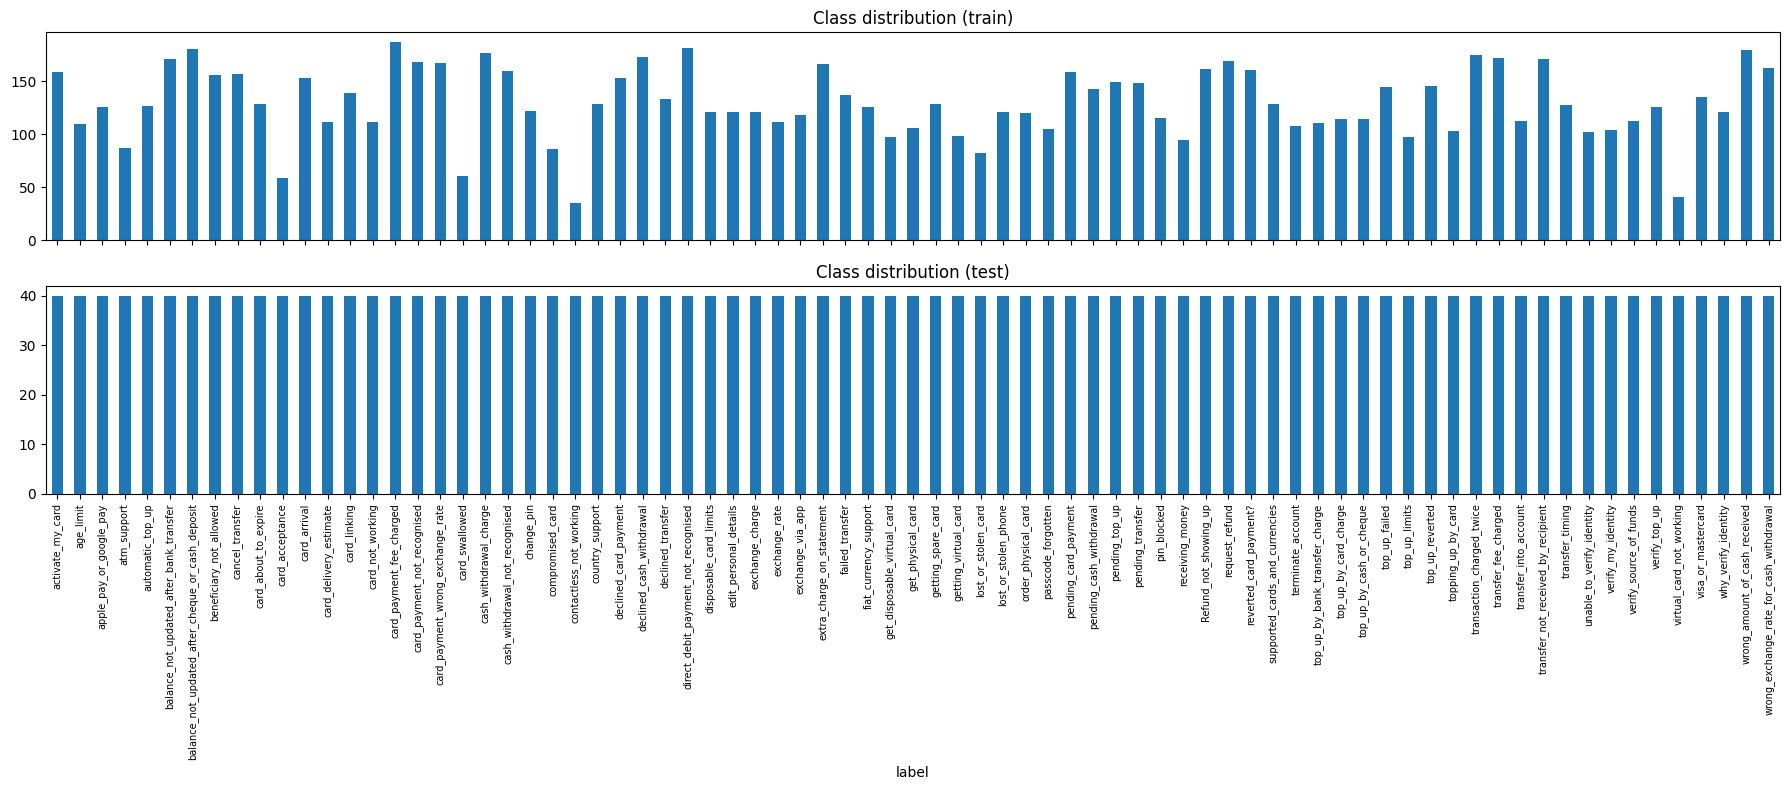

Train class counts: min 35 (contactless_not_working), max 187 (card_payment_fee_charged)


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(18, 8), sharex=True)
for ax, (name, df_split) in zip(axes, [("train", df_train_raw), ("test", df_test_raw)]):
    df_split["label"].value_counts().sort_index().plot.bar(ax=ax, title=f"Class distribution ({name})")
axes[1].set_xticklabels(label_names, rotation=90, fontsize=7)
plt.tight_layout()
plt.show()

class_counts = df_train_raw["label"].value_counts()
print(f"Train class counts: min {class_counts.min()} ({label_names[class_counts.idxmin()]}), "
      f"max {class_counts.max()} ({label_names[class_counts.idxmax()]})")

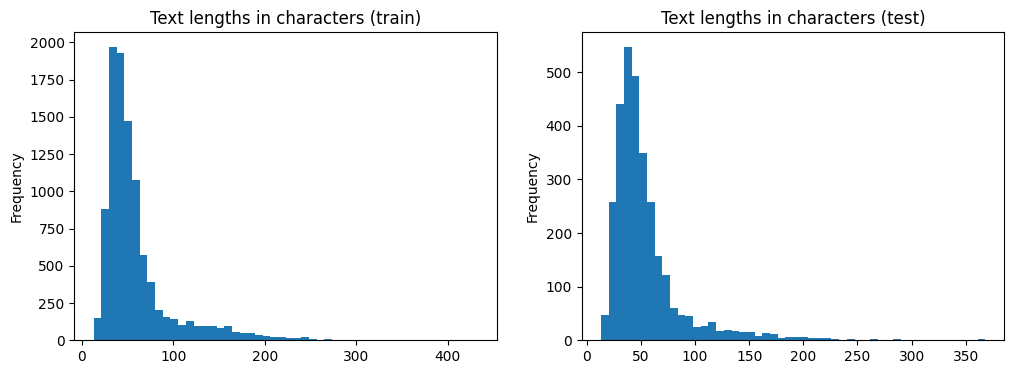

count    10003.000000
mean        59.473758
std         40.867901
min         13.000000
25%         36.000000
50%         47.000000
75%         64.000000
max        433.000000
Name: text, dtype: float64

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, (name, df_split) in zip(axes, [("train", df_train_raw), ("test", df_test_raw)]):
    df_split["text"].str.len().plot.hist(bins=50, ax=ax, title=f"Text lengths in characters ({name})")
plt.show()

df_train_raw["text"].str.len().describe()

In [6]:
def clean_texts(df_split: pd.DataFrame) -> pd.DataFrame:
    df_clean = df_split.copy()
    df_clean["text"] = df_clean["text"].str.strip()
    df_clean = df_clean[df_clean["text"].str.len() > 0]
    df_clean = df_clean[~df_clean["text"].str.lower().duplicated()]
    return df_clean.reset_index(drop=True)


df_train = clean_texts(df_train_raw)
df_test = clean_texts(df_test_raw)

# remove train texts leaking into the test set
df_train = df_train[~df_train["text"].str.lower().isin(set(df_test["text"].str.lower()))].reset_index(drop=True)

print("Train after cleaning:", len(df_train))
print("Test after cleaning:", len(df_test))

Train after cleaning: 9993
Test after cleaning: 3079


Data is clean at first glance: no missing or empty texts, only 4 (train) and 1 (test) case-insensitive duplicates, and 6 train texts leaking into the test set (removed from train). Classes are imbalanced (35-187 train samples per class), texts are short (median 47 characters) with a long tail up to ~430.

## 2. CleanLab data quality

In [7]:
from cleanlab import Datalab
from sentence_transformers import SentenceTransformer
from sklearn.linear_model import LogisticRegressionCV
from sklearn.model_selection import cross_val_predict


def get_initial_model_data(texts: np.ndarray, labels: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    encoder = SentenceTransformer("all-MiniLM-L6-v2", device=device)
    embeddings = encoder.encode(texts, show_progress_bar=True)
    classifier = LogisticRegressionCV(Cs=5, cv=3, class_weight="balanced", max_iter=1000, n_jobs=NUM_CORES)
    pred_probs = cross_val_predict(classifier, embeddings, labels, cv=5, method="predict_proba")
    return embeddings, pred_probs


texts = df_train["text"].values
labels = df_train["label"].values
embeddings, pred_probs = get_initial_model_data(texts, labels)
print(f"Initial model cross-validated accuracy: {(pred_probs.argmax(axis=1) == labels).mean():.2%}")

Batches:   0%|          | 0/313 [00:00<?, ?it/s]

Initial model cross-validated accuracy: 91.96%


In [8]:
lab = Datalab({"texts": texts, "labels": labels}, label_name="labels", task="classification")
lab.find_issues(pred_probs=pred_probs, features=embeddings, issue_types={"label": {}, "near_duplicate": {}, "outlier": {}})
lab.report()

Finding label issues ...


Finding near_duplicate issues ...


Finding outlier issues ...

Audit complete. 683 issues found in the dataset.
Dataset Information: num_examples: 9993, num_classes: 77

Here is a summary of various issues found in your data:

    issue_type  num_issues
near_duplicate         341
         label         210
       outlier         132

Learn about each issue: https://docs.cleanlab.ai/stable/cleanlab/datalab/guide/issue_type_description.html
See which examples in your dataset exhibit each issue via: `datalab.get_issues(<ISSUE_NAME>)`

Data indices corresponding to top examples of each issue are shown below.


------------------ near_duplicate issues -------------------

About this issue:
	A (near) duplicate issue refers to two or more examples in
    a dataset that are extremely similar to each other, relative
    to the rest of the dataset.  The examples flagged with this issue
    may be exactly duplicated, or lie atypically close together when
    represented as vectors (i.e. feature embeddings).
    

Number of example

### Label issues

In [9]:
label_issues = lab.get_issues("label")
label_issues = label_issues[label_issues["is_label_issue"]].sort_values(by="label_score")
print("Label issues:", len(label_issues), f"({len(label_issues) / len(df_train):.2%})")

for idx, row in label_issues.head(20).iterrows():
    print(f"{label_names[row['given_label']]} -> {label_names[row['predicted_label']]}: {texts[idx]}")

Label issues: 210 (2.10%)
card_arrival -> card_not_working: WHAT IS THE SOLUTION OF THIS PROBLEM
top_up_limits -> top_up_by_cash_or_cheque: I need to add a serious amount of cash to my card, how do I do that?
disposable_card_limits -> getting_virtual_card: i am not a premium customer but i want a virtual card, how do i get it
lost_or_stolen_card -> card_arrival: Can you tell me the status of my new card?
declined_transfer -> beneficiary_not_allowed: please help me with this transfer, for some reason i can't transfer to a cryptocurency account
declined_cash_withdrawal -> card_not_working: Is my card actually working? It's the first time I tried using it
pin_blocked -> get_physical_card: Where do I find PIN for my card?
card_not_working -> pin_blocked: Can I use app to reset PIN attempts?
balance_not_updated_after_bank_transfer -> pending_transfer: My transfer is pending too long.
card_arrival -> card_delivery_estimate: maximum how many days get the courier?
pending_top_up -> topping_up_

In [10]:
confused_pairs = label_issues.apply(lambda row: f"{label_names[row['given_label']]} -> {label_names[row['predicted_label']]}", axis=1)
confused_pairs.value_counts().head(15)

wrong_exchange_rate_for_cash_withdrawal -> card_payment_wrong_exchange_rate      9
top_up_reverted -> top_up_failed                                                 7
pending_transfer -> balance_not_updated_after_bank_transfer                      5
compromised_card -> lost_or_stolen_card                                          4
why_verify_identity -> verify_my_identity                                        4
balance_not_updated_after_bank_transfer -> transfer_not_received_by_recipient    4
card_delivery_estimate -> card_arrival                                           4
pending_top_up -> top_up_failed                                                  4
top_up_failed -> pending_top_up                                                  4
transfer_timing -> balance_not_updated_after_bank_transfer                       4
reverted_card_payment? -> declined_card_payment                                  4
pending_transfer -> transfer_not_received_by_recipient                           4
cash

### Near duplicates

In [11]:
duplicate_issues = lab.get_issues("near_duplicate")
duplicate_issues = duplicate_issues[duplicate_issues["is_near_duplicate_issue"]].sort_values(by="near_duplicate_score")
print("Near duplicate issues:", len(duplicate_issues), f"({len(duplicate_issues) / len(df_train):.2%})")

for idx, row in duplicate_issues.head(10).iterrows():
    print(f"[{label_names[labels[idx]]}] {texts[idx]}")
    for neighbor_idx in row["near_duplicate_sets"][:3]:
        print(f"\t[{label_names[labels[neighbor_idx]]}] {df_train.iloc[neighbor_idx]['text']}")

Near duplicate issues: 341 (3.41%)
[passcode_forgotten] How can i reset my passcode ?
	[passcode_forgotten] How can I reset my passcode?
	[passcode_forgotten] How do I reset my passcode?
[declined_card_payment] Why do you keep declining my payment? I tried several times already with this card and it is just not working.
	[declined_card_payment] Why do you keep declining my payment?I tried several times already with this card and it is just not working.
	[declined_card_payment] Why do you keep declining my payment?I tried several times with this card and it is just not working.
[declined_card_payment] Why do you keep declining my payment?I tried several times already with this card and it is just not working.
	[declined_card_payment] Why do you keep declining my payment? I tried several times already with this card and it is just not working.
	[declined_card_payment] Why do you keep declining my payment?I tried several times with this card and it is just not working.
[passcode_forgotten

In [12]:
for idx, row in duplicate_issues.tail(5).iterrows():
    print(f"[{label_names[labels[idx]]}] {texts[idx]}")
    for neighbor_idx in row["near_duplicate_sets"][:3]:
        print(f"\t[{label_names[labels[neighbor_idx]]}] {df_train.iloc[neighbor_idx]['text']}")

[disposable_card_limits] Is there a limit to a disposable virtual card?
	[disposable_card_limits] Is there a limit to using a disposable virtual card?
[disposable_card_limits] Is there a limit to using a disposable virtual card?
	[disposable_card_limits] Is there a limit to a disposable virtual card?
[top_up_limits] Can I top-up any amount?
	[top_up_limits] Can I top up any amount?
[top_up_limits] Can I top up any amount?
	[top_up_limits] Can I top-up any amount?
[transfer_timing] How long will a transfer from the US take?
	[transfer_timing] How long does a transfer from the US take?


### Outliers

In [13]:
outlier_issues = lab.get_issues("outlier")
outlier_issues = outlier_issues[outlier_issues["is_outlier_issue"]].sort_values(by="outlier_score")
print("Outlier issues:", len(outlier_issues), f"({len(outlier_issues) / len(df_train):.2%})")

for idx, row in outlier_issues.head(15).iterrows():
    print(f"score {row['outlier_score']:.4f} [{label_names[labels[idx]]}] {texts[idx]}")

Outlier issues: 132 (1.32%)
score 0.0051 [card_acceptance] WHAT IS THE ATMOSPHERE OF IT
score 0.0063 [direct_debit_payment_not_recognised] what is the word?
score 0.0079 [cash_withdrawal_not_recognised] What is this witdrawal
score 0.0080 [direct_debit_payment_not_recognised] what is the matter?
score 0.0088 [card_arrival] WHAT IS THE SOLUTION OF THIS PROBLEM
score 0.0107 [visa_or_mastercard] I prefer Mastecard.
score 0.0164 [failed_transfer] I have made 5 attempts to make a very standard survey, yet I can't get it to work. What is the problem? Is there an issue related to your system?
score 0.0167 [card_not_working] WHAT IS THE MAIN REASON OF THIS PROBLEM
score 0.0169 [card_not_working] WHAT IS THE REASON FOR THAT
score 0.0190 [transfer_fee_charged] why was i chargged
score 0.0202 [pending_transfer] I have a trasnger that is pending and wondered about it.
score 0.0203 [country_support] As far as courtries go which ones are supported?
score 0.0226 [change_pin] How can I change my Rowlo

### Fixing issues

In [14]:
# keep a single sample from each near duplicate set
near_duplicates_to_drop = {
    idx for idx, row in duplicate_issues.iterrows()
    if any(neighbor_idx < idx for neighbor_idx in row["near_duplicate_sets"])
}
outliers_to_drop = set(outlier_issues.index)

df_train_fixed = df_train.copy()
df_train_fixed.loc[label_issues.index, "label"] = label_issues["predicted_label"]
df_train_fixed = df_train_fixed.drop(index=list(near_duplicates_to_drop | outliers_to_drop)).reset_index(drop=True)

print("Relabeled:", len(label_issues))
print("Dropped near duplicates:", len(near_duplicates_to_drop))
print("Dropped outliers:", len(outliers_to_drop))
print("Train after fixing:", len(df_train_fixed))

Relabeled: 210
Dropped near duplicates: 181
Dropped outliers: 132
Train after fixing: 9680


- Agreement with the paper: yes, qualitatively. Most label issues are confusions between semantically overlapping intents (`top_up_reverted`/`top_up_failed`, `pending_transfer`/`balance_not_updated_after_bank_transfer`, `card_delivery_estimate`/`card_arrival`, `why_verify_identity`/`verify_my_identity`), exactly the kind of ambiguous and mislabeled samples the paper reports. The 2.1% flagged here is a lower bound, since the initial model (92% CV accuracy) also confuses those intents.
- Near duplicates (3.4%) are mostly paraphrases differing by punctuation or a single word - harmless but they overweight some samples. Outliers are generic texts without intent ("WHAT IS THE SOLUTION OF THIS PROBLEM") and typos.
- Severity: moderate. Label noise between overlapping intents directly hurts the hardest classes, so it is worth fixing; duplicates and outliers are a minor problem. Blindly relabeling with the initial model's predictions is risky, ideally the flagged samples would be reviewed manually.

## 3. Text classifier training

In [15]:
from datasets import Dataset, DatasetDict
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

MODEL_NAME = "distilbert/distilbert-base-uncased"

df_train_split, df_valid_split = train_test_split(
    df_train_fixed, test_size=0.2, random_state=0, stratify=df_train_fixed["label"]
)

datasets_dict = DatasetDict({
    "train": Dataset.from_pandas(df_train_split, preserve_index=False),
    "valid": Dataset.from_pandas(df_valid_split, preserve_index=False),
    "test": Dataset.from_pandas(df_test, preserve_index=False),
})

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)


def tokenize(examples: dict) -> dict:
    return tokenizer(examples["text"], truncation=True)


datasets_tokenized = datasets_dict.map(tokenize, batched=True)
datasets_tokenized

Map:   0%|          | 0/7744 [00:00<?, ? examples/s]

Map:   0%|          | 0/1936 [00:00<?, ? examples/s]

Map:   0%|          | 0/3079 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 7744
    })
    valid: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 1936
    })
    test: Dataset({
        features: ['text', 'label', 'input_ids', 'attention_mask'],
        num_rows: 3079
    })
})

In [16]:
import random

from sklearn.metrics import f1_score
from torch.nn.functional import softmax
from transformers import AutoModelForSequenceClassification, DataCollatorWithPadding, EvalPrediction, Trainer, TrainingArguments

os.environ["PYTHONHASHSEED"] = str(0)
random.seed(0)
np.random.seed(0)
torch.manual_seed(0)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=NUM_LABELS,
    id2label=dict(enumerate(label_names)),
    label2id={name: idx for idx, name in enumerate(label_names)},
)


def get_predictions(logits: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    y_pred_proba = softmax(torch.from_numpy(logits), dim=1).numpy()
    y_pred = np.argmax(y_pred_proba, axis=1)
    return y_pred_proba, y_pred


def compute_metrics(eval_pred: EvalPrediction) -> dict:
    _, y_pred = get_predictions(eval_pred.predictions)
    return {"f1": f1_score(eval_pred.label_ids, y_pred, average="macro")}


training_args = TrainingArguments(
    output_dir="finetuned_model_homework",
    learning_rate=1e-4,
    num_train_epochs=10,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    warmup_ratio=0.1,
    weight_decay=0.01,
    eval_strategy="epoch",
    save_strategy="epoch",
    save_total_limit=1,
    load_best_model_at_end=True,
    metric_for_best_model="f1",
    logging_strategy="epoch",
    report_to="none",
    seed=0,
    data_seed=0,
)

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=datasets_tokenized["train"],
    eval_dataset=datasets_tokenized["valid"],
    data_collator=DataCollatorWithPadding(tokenizer),
    compute_metrics=compute_metrics,
)
trainer.train()

Some weights of DistilBertForSequenceClassification were not initialized from the model checkpoint at distilbert/distilbert-base-uncased and are newly initialized: ['classifier.bias', 'classifier.weight', 'pre_classifier.bias', 'pre_classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Epoch,Training Loss,Validation Loss,F1
1,3.243900,1.213930,0.706278
2,0.636500,0.369690,0.899765
3,0.210700,0.319325,0.907095
4,0.098000,0.326196,0.915761
5,0.047000,0.317893,0.925148
6,0.022200,0.320718,0.932753
7,0.007100,0.305078,0.934142
8,0.003300,0.307779,0.934407
9,0.001700,0.307428,0.933808
10,0.001500,0.308532,0.933344


TrainOutput(global_step=2420, training_loss=0.4271919300364069, metrics={'train_runtime': 749.4579, 'train_samples_per_second': 103.328, 'train_steps_per_second': 3.229, 'total_flos': 923662216472640.0, 'train_loss': 0.4271919300364069, 'epoch': 10.0})